# one-snapshot FK heat flux and submesoscale heat flux

In [39]:
# --------------------- your submesoscale heat flux (DO NOT MODIFY) -------------------
import xarray as xr

def submeso_vertical_heat_flux(
    ds_fine: xr.Dataset,
    ds_ocean: xr.Dataset,
    boundary_Z: str = "fill",
    to_wm2=True, 
):
    """
    compute the total heat flux
    """
    # merge the two dataset
    ds = xr.merge([ds_fine, ds_ocean])
    grid_fine = make_grid.make_grid_periodic_x(ds)
    # ---------- Build open interface area Aface (k_l,j,i) ----------
    # open_frac(k_l) = min(hFacC_k, hFacC_{k+1})
    upper = ds["hFacC"]                                  # (k,j,i)
    lower = ds["hFacC"].shift(k=-1, fill_value=0.0)      # (k+1,j,i)
    open_frac = xr.ufuncs.minimum(upper, lower).rename({'k': 'k_l'})  # (k_l,j,i)
    Aface = (open_frac * ds["RAC"]).astype('float32')                 # (k_l,j,i)
    # Valid interface mask (avoid coast/land)
    wet_w = Aface > 0

    # high resolution vertical heat flux
    # put T on W-interfaces
    T_w = grid_fine.interp(ds["T"], "Z", to="left", boundary=boundary_Z) # (k_l,j,i)
    print("W dims:", ds["W"].dims, ds["W"].shape)
    print("T dims:", ds["T"].dims, ds["T"].shape)
    print("T_w dims:", T_w.dims, T_w.shape)
    WT  = ds["W"] * T_w # (k_l,j,i)
    
    # Interpolate in vertical from k_l → k AFTER coarse-graining
    wT_kC = grid_fine.interp(WT, "Z", to="center",
                            boundary=boundary_Z).rename("wT_sub_kC")

    # ---------- Units: convert to W m^-2 if requested ----------
    if to_wm2:
        rho0, cp = 1035.0, 3994.0  # kg m^-3, J kg^-1 K^-1
        wT_kC = (rho0 * cp * wT_kC).assign_attrs(units="W m^-2")
    else:
        for da in (wT_sub_kL, wT_bar_kL, wT_sub_kC):
            da.attrs['units'] = "K m s^-1"

    # Some helpful long_names
    wT_kC.attrs['long_name'] = "heat flux"

    return wT_kC

In [40]:
import numpy as np
import xarray as xr
from MITgcmutils import mds

def mean_12h_var_special(
    grid_dir: str,
    varname: str,
    start_time: int,
    dims: tuple[str, ...],
    *,
    ds_grid: xr.Dataset,
    snapshots_per_12h: int = 12,
    time_step: int = 18,
    diag_dir: str | None = None,
    field_index_kpphbl: int = 1,
):
    """
    Compute a 12-hour mean field from MITgcm outputs.

    Special cases:
      - varname == "Wstar_FK": compute from GM_diags
      - varname == "kpphbl":   load from DiagMXL_2d using mds.rdmds

    Parameters
    ----------
    grid_dir : str
        MITgcm run directory.
    varname : str
        Variable name.
    start_time : int
        Iteration of the first snapshot in the 12-hour averaging window.
    dims : tuple[str, ...]
        Dimensions for read_mitgcm._ocean_var, e.g. ("k_l","j","i").
        Ignored for special branches.
    ds_grid : xr.Dataset
        Grid dataset used to build xgcm grid and access metrics.
    snapshots_per_12h : int
        Number of snapshots to average. Default 12.
    time_step : int
        Iteration spacing between snapshots. Default 144.
    diag_dir : str | None
        Directory containing diagnostic files. If None, defaults to
        grid_dir + "Diags/".
    field_index_kpphbl : int
        Field index inside DiagMXL_2d for kpphbl. Default 1.

    Returns
    -------
    xr.DataArray
        12-hour mean field.
    """
    grid = make_grid.make_grid_periodic_x(ds_grid)

    if diag_dir is None:
        diag_dir = grid_dir + "Diags/"

    fields = []
    time_index = []

    for n in range(snapshots_per_12h):
        it = start_time + n * time_step

        if varname == "Wstar_FK":
            # -----------------------------------
            # special case 1: compute Wstar_FK
            # -----------------------------------
            GM_diags_FK = mds.rdmds(diag_dir + "GM_diags", it)

            psiX_FK = GM_diags_FK[0, ...]   # (k, j, i_g)
            psiY_FK = GM_diags_FK[1, ...]   # (k, j_g, i)

            psiX_FK = xr.DataArray(psiX_FK, dims=("k", "j", "i_g"))
            psiY_FK = xr.DataArray(psiY_FK, dims=("k", "j_g", "i"))

            dPsiY_dx_FK = (psiY_FK.roll(i=-1, roll_coords=False) - psiY_FK) / ds_grid["DXG"]
            dPsiX_dy_FK = (psiX_FK.shift(j=-1) - psiX_FK) / ds_grid["DYG"]

            dPsiY_dx_c_FK = grid.interp(dPsiY_dx_FK, "Y", boundary="fill")
            dPsiX_dy_c_FK = grid.interp(dPsiX_dy_FK, "X", boundary="periodic")

            da = (dPsiY_dx_c_FK - dPsiX_dy_c_FK).rename("Wstar_FK")

        elif varname == "kpphbl":
            # -----------------------------------
            # special case 2: load kpphbl from DiagMXL_2d
            # -----------------------------------
            diagMXL = mds.rdmds(diag_dir + "DiagMXL_2d", it)  # (nfields, j, i)
            da = xr.DataArray(
                diagMXL[field_index_kpphbl, :, :],
                dims=("j", "i"),
                name="kpphbl",
            )

        else:
            # -----------------------------------
            # default case: normal MITgcm variable
            # -----------------------------------
            da = read_mitgcm._ocean_var(grid_dir, varname, it, dims)
            da = da.drop_vars("time", errors="ignore")
            da.name = varname

        fields.append(da)
        time_index.append(it)

    out = xr.concat(
        fields,
        dim=xr.DataArray(time_index, dims="time", name="time")
    )

    out_mean = out.mean(dim="time", skipna=True)
    out_mean.name = varname
    out_mean.attrs["origin_iter"] = start_time
    out_mean.attrs["snapshots_used"] = snapshots_per_12h
    out_mean.attrs["time_step"] = time_step
    out_mean.attrs["mean_window"] = "12h"

    return out_mean

In [36]:
# load the w_bg, w_fk, T_bg
import os
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))
from src.utils import make_grid
from src.utils import build_coarse_grid
from src.utils import read_mitgcm
import xarray as xr
import numpy as np
from src.utils import coarsen_UVWTS
from MITgcmutils import mds
from src.utils import mld_avg
import gsw

# --------------------- MITgcm folder path ----------------------------------
path_scratch = '/scratch/jczhang/'
path_MITgcm = 'MITgcm_50km_FK/verification/tutorial_reentrant_channel/run/'
grid_dir = path_scratch + path_MITgcm

# --------------------- grid variable ----------------------------------
ds = read_mitgcm.read_mitgrid_staggered(grid_dir)
start_time = 2021760

#----------------------------------------- background heat flux ----------------------------------
W_12h = mean_12h_var_special(
    grid_dir=grid_dir,
    varname="W",
    start_time=start_time,
    dims=("k_l", "j", "i"),
    ds_grid = ds
)
T_12h = mean_12h_var_special(
    grid_dir=grid_dir,
    varname="T",
    start_time=start_time,
    dims=("k", "j", "i"),
    ds_grid = ds
)
ds_ocean = xr.Dataset(dict(W=W_12h, T=T_12h))
wT = submeso_vertical_heat_flux(ds, ds_ocean, boundary_Z = "fill", to_wm2 = True)
#----------------------------------------- FK heat flux ----------------------------------
Wstar_FK_12h = mean_12h_var_special(
    grid_dir=grid_dir,
    varname="Wstar_FK",
    start_time=start_time,
    dims=(),   # ignored in this branch
    ds_grid=ds,
)

In [28]:
# now load the corresponding SubmesoFluxNet input variables
from src.utils import vel
from src.utils import strain
from src.utils import vorticity
from src.utils import mld_avg
from src.utils import make_grid
kpphbl_12h = mean_12h_var_special(
    grid_dir=grid_dir,
    varname="kpphbl",
    start_time=start_time,
    dims=("j", "i"),
    ds_grid = ds,
)
#  U, V, W, kpphbl, speed, strain, vorticity, and T
# load U and save the mld averaged U
U_12h = mean_12h_var_special(
    grid_dir=grid_dir,
    varname="U",
    start_time=start_time,
    dims=("k", "j", "i_g"),
    ds_grid = ds
)
# load V
V_12h = mean_12h_var_special(
    grid_dir=grid_dir,
    varname="V",
    start_time=start_time,
    dims=("k", "j_g", "i"),
    ds_grid = ds
)
V_12h_mld = mld_avg.mld_avg(V_12h, kpphbl_12h, ds)
# ds_ocean 
ds_ocean = xr.Dataset(dict(W=W_12h, T=T_12h, U=U_12h, V=V_12h))
# calculate the speed
boundary_Y = "fill"
speed_12h = vel._horizontal_speed(ds, ds_ocean, boundary_Y=boundary_Y)
strain_12h = strain._total_strain(ds, ds_ocean, boundary_Y=boundary_Y)
zeta_12h =  vorticity._vorticity(ds, ds_ocean, boundary_Y=boundary_Y)
# take mld_avg
grid = make_grid.make_grid_periodic_x(ds)
U_12h = grid.interp(U_12h, "X", to="center", boundary="fill") # (k_l,j,i)
U_mld = mld_avg.mld_avg(U_12h, kpphbl_12h, ds)
V_12h = grid.interp(V_12h, "Y", to="center", boundary="fill") # (k_l,j,i)
V_mld = mld_avg.mld_avg(V_12h, kpphbl_12h, ds)
W_12h = grid.interp(W_12h, "Z", to="center", boundary="fill") # (k_l,j,i)
W_mld = mld_avg.mld_avg(W_12h, kpphbl_12h, ds)
T_mld = mld_avg.mld_avg(T_12h, kpphbl_12h, ds)
kpphbl_mld = kpphbl_12h
speed_mld = mld_avg.mld_avg(speed_12h, kpphbl_12h, ds)
strain_mld = mld_avg.mld_avg(strain_12h, kpphbl_12h, ds)
zeta_mld = mld_avg.mld_avg(zeta_12h, kpphbl_12h, ds)

In [30]:
print(U_mld.shape)

(120, 60)


In [29]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

import numpy as np
import torch

from src.models.UNet_ConvLSTM_4En4De_pixel import UNetPhysDepth1


def load_unet_checkpoint(ckpt_path, device):
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)

    # build model to match training
    model = UNetPhysDepth1(
        input_channels=8,
        head_channel=1,
        base=256,
        kernel_size=3,
        activation="SiLU",
        batch_norm="bn",
        dropout_2D=0.2,
        use_lstm=False,
        lstm_dropout=0.15,
    ).to(device)

    model.load_state_dict(ckpt["model"], strict=True)
    model.eval()

    norm = ckpt.get("norm", None)
    return model, norm


@torch.no_grad()
def predict_single_unet(model, X_single, device, X_mu=None, X_sd=None, y_mu=None, y_sd=None):
    """
    X_single: (C,H,W)
    returns y_pred: (1,1,H,W)
    """
    X_single = np.asarray(X_single, dtype=np.float32)

    if X_single.ndim != 3:
        raise ValueError(f"X_single must be (C,H,W), got {X_single.shape}")

    if X_mu is not None and X_sd is not None:
        X_single = (X_single - X_mu) / (X_sd + 1e-12)

    x = torch.from_numpy(X_single).unsqueeze(0).to(device)   # (1,C,H,W)
    y_pred = model(x).cpu().numpy()                          # (1,1,H,W)

    if y_mu is not None and y_sd is not None:
        y_pred = y_pred * (y_sd + 1e-12) + y_mu

    return y_pred

In [34]:
# ----------------------------
# example: build your 7-channel input
# all inputs should already be 2D with same shape, e.g. (56,56)
# ----------------------------
X_single = np.stack([
    np.asarray(U_mld[62:118, 2:58]),
    np.asarray(V_mld[62:118, 2:58]),
    np.asarray(W_mld[62:118, 2:58]),
    np.asarray(zeta_mld[62:118, 2:58]),
    np.asarray(strain_mld[62:118, 2:58]),
    np.asarray(T_mld[62:118, 2:58]),
    np.asarray(speed_mld[62:118, 2:58]),
    np.asarray(kpphbl_mld[62:118, 2:58]),
], axis=0)   # shape (7,H,W)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model, norm = load_unet_checkpoint(
    "/scratch/jczhang/submeso_data_driven/check_point/cfg_19/best_unet_conv.pt",
    device
)

X_mu = norm["X_mu"]
X_sd = norm["X_sd"]
y_mu = norm["y_mu"]
y_sd = norm["y_sd"]

y_pred = predict_single_unet(
    model,
    X_single,
    device,
    X_mu=X_mu,
    X_sd=X_sd,
    y_mu=y_mu,
    y_sd=y_sd,
)

print(y_pred.shape)   # (1,1,H,W)

pred_map = y_pred[0, 0]

(1, 1, 56, 56)


In [50]:
print(X_mu)

[[[[ 2.0874780e-02]]

  [[ 2.2412123e-02]]

  [[-3.7394526e-07]]

  [[ 1.9984043e-07]]

  [[ 3.1085842e-06]]

  [[ 4.2441597e+00]]

  [[ 3.8939407e-01]]

  [[ 7.3342140e+01]]]]


In [38]:
print(W_12h)

<xarray.DataArray 'W' (k_l: 49, j: 120, i: 60)> Size: 3MB
array([[[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 1.52932725e-06,  1.58022082e-06,  1.64612144e-06, ...,
          1.36251313e-06,  1.42681301e-06,  1.47992471e-06],
        [ 1.53523441e-06,  1.61485445e-06,  1.71410443e-06, ...,
          1.36048952e-06,  1.41950760e-06,  1.47262038e-06],
        ...,
        [-1.62005660e-07, -1.62050172e-07, -1.60773932e-07, ...,
         -1.52911679e-07, -1.56562281e-07, -1.60510162e-07],
        [-1.71862094e-07, -1.71436138e-07, -1.69884783e-07, ...,
         -1.67389296e-07, -1.68975781e-07, -1.70879710e-07],
        [-1.85448442e-07, -1.86310829e-07, -1.87498867e-07, ...,
         -1.80530217e-07, -1.82263875e-07, -1.84233594e-07]],

       [[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
          0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 1.89944696e-06,  2.11115669e-06,  1

In [43]:
# calculate the fk and bg heat 
var_bg = xr.Dataset(dict(W=W_12h, T=T_12h))
wT_bg = submeso_vertical_heat_flux(ds, var_bg, "fill", True)
wT_bg_mld = mld_avg.mld_avg(wT_bg, kpphbl_12h, ds)
Wstar_FK_12h = grid.interp(Wstar_FK_12h, "Z", to="left", boundary="fill") # (k_l,j,i)
var_fk = xr.Dataset(dict(W=Wstar_FK_12h, T=T_12h))   
wT_fk = submeso_vertical_heat_flux(ds, var_fk, "fill", True)
wT_fk_mld = mld_avg.mld_avg(wT_fk, kpphbl_12h, ds)



W dims: ('k_l', 'j', 'i') (49, 120, 60)
T dims: ('k', 'j', 'i') (49, 120, 60)
T_w dims: ('k_l', 'j', 'i') (49, 120, 60)
W dims: ('k_l', 'j', 'i') (49, 120, 60)
T dims: ('k', 'j', 'i') (49, 120, 60)
T_w dims: ('k_l', 'j', 'i') (49, 120, 60)


In [44]:
a = pred_map
b = wT_fk_mld[62:118,2:58]
c = wT_bg_mld[62:118,2:58]

print(b.shape)

(56, 56)


In [45]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import cmocean.cm as cmo

def sym_limit(*arrays, q=0.995):
    vals = []
    for a in arrays:
        a = np.asarray(a)
        vals.append(np.abs(a[np.isfinite(a)]).ravel())
    vals = np.concatenate(vals)
    return float(np.nanquantile(vals, q))

def plot_three_flux_maps(pred, fk, background, q=0.995, savepath=None):
    pred = np.asarray(pred)
    fk = np.asarray(fk)
    background = np.asarray(background)

    if pred.shape != (56, 56):
        raise ValueError(f"pred shape is {pred.shape}, expected (56, 56)")
    if fk.shape != (56, 56):
        raise ValueError(f"fk shape is {fk.shape}, expected (56, 56)")
    if background.shape != (56, 56):
        raise ValueError(f"background shape is {background.shape}, expected (56, 56)")

    clim = sym_limit(pred, fk, background, q=q)
    norm = TwoSlopeNorm(vcenter=0.0, vmin=-clim, vmax=clim)

    fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), constrained_layout=True)

    im0 = axes[0].imshow(pred, origin="lower", cmap=cmo.balance, norm=norm)
    axes[0].set_title("SubmesoFluxNet", fontsize=13)

    im1 = axes[1].imshow(fk, origin="lower", cmap=cmo.balance, norm=norm)
    axes[1].set_title("Fox-Kemper", fontsize=13)

    im2 = axes[2].imshow(background, origin="lower", cmap=cmo.balance, norm=norm)
    axes[2].set_title("Background", fontsize=13)

    panel_labels = ["(a)", "(b)", "(c)"]
    for ax, lab in zip(axes, panel_labels):
        ax.text(
            0.02, 0.98, lab,
            transform=ax.transAxes,
            ha="left", va="top",
            fontsize=13, fontweight="bold"
        )
        ax.set_xticks([])
        ax.set_yticks([])

    cbar = fig.colorbar(im2, ax=axes, shrink=0.9, pad=0.03)
    cbar.set_label(r"Heat flux [$\mathrm{W\,m^{-2}}$]", fontsize=12)

    if savepath is not None:
        plt.savefig(savepath, dpi=300, bbox_inches="tight")

    plt.show()

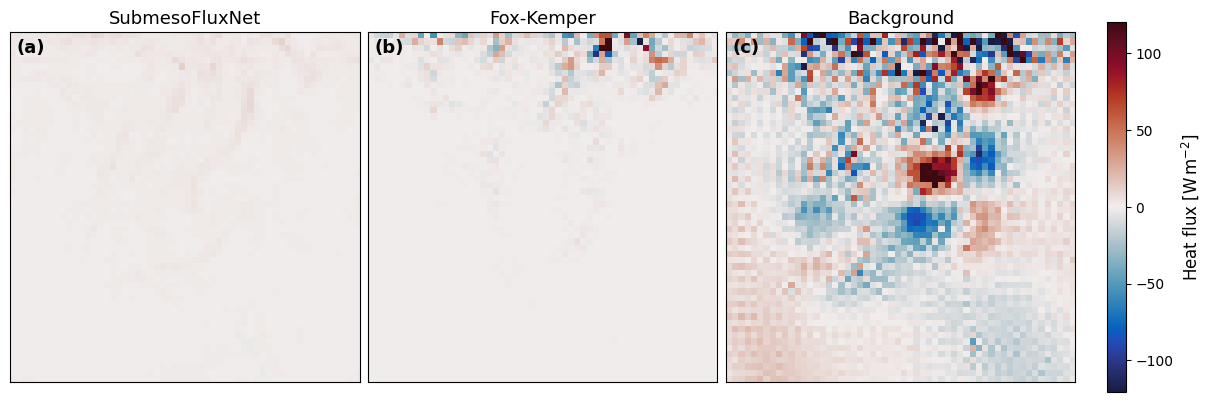

In [47]:
plot_three_flux_maps(
    pred=a,
    fk=b,
    background=c,
    savepath="pred_fk_background.png",
)